# Data Exploration and Preprocessing

In [ ]:
from pathlib import Path

# Project folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_DIR = ROOT / "data_cleaned"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
print("Raw data folder:", ROOT)
print("Cleaned data folder:", CLEAN_DIR)

Raw data folder: /media/lucho/Data/IMT-26-27/machine_learning/challenge
Cleaned data folder: /media/lucho/Data/IMT-26-27/machine_learning/challenge/data_cleaned


# 1. Cities (`cities.csv`)

### 1. Load the data

`pd.read_csv()` reads a CSV file into a pandas DataFrame, which is a table.
The project folder (`ROOT`) is defined once in the setup cell at the top of this notebook.

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Project folder (ROOT is defined in the setup cell).
project_folder = str(ROOT)

cities = pd.read_csv(project_folder + "/cities.csv")
cities.head()

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


In [3]:
# Show the number of rows and columns.
print("Rows:", cities.shape[0])
print("Columns:", cities.shape[1])

# Show column names, data types, and non-missing counts.
cities.info()

Rows: 267
Columns: 7
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    str    
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    str    
 5   country                  267 non-null    str    
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), str(3)
memory usage: 19.5 KB


### 2. Check data quality

Check missing values before deciding how to handle them. Also check duplicate rows and duplicate IDs.
An ID should identify only one scheme.

In [4]:
# Count missing values in each column.
cities.isna().sum()

id                         0
name                       0
lat                        0
lon                        0
timezone                   0
country                    0
return_to_official_only    0
dtype: int64

In [5]:
print("Duplicate rows:", cities.duplicated().sum())
print("Duplicate IDs:", cities["id"].duplicated().sum())

# Count names with spaces at the beginning or end.
extra_spaces = cities["name"] != cities["name"].str.strip()
print("Names with extra spaces:", extra_spaces.sum())

cities.loc[extra_spaces, ["id", "name"]]

Duplicate rows: 0
Duplicate IDs: 0
Names with extra spaces: 2


,id,name
64,745,Stari Grad
143,617,Split


In [6]:
# Valid latitude is between -90 and 90.
# Valid longitude is between -180 and 180.
invalid_coordinates = cities[
    ~cities["lat"].between(-90, 90)
    | ~cities["lon"].between(-180, 180)
]

print("Rows with missing or out-of-range coordinates:", len(invalid_coordinates))
invalid_coordinates

Rows with missing or out-of-range coordinates: 0


,id,name,lat,lon,timezone,country,return_to_official_only


**Results:** The supplied data contains 267 rows and 7 columns. There are no missing values,
no duplicate rows, no duplicate IDs, and no missing or out-of-range coordinates.
Two scheme names have trailing spaces. No missing-value imputation is needed for this file.

### 3. Clean the data

Make a copy so the original table stays available for comparison. Remove extra spaces,
standardize country codes to uppercase, and remove exact duplicate rows if any exist.
Do not delete different IDs just because they have the same location.

In [7]:
cities_clean = cities.copy()

# Remove spaces at the beginning and end of text values.
cities_clean["name"] = cities_clean["name"].str.strip()
cities_clean["country"] = cities_clean["country"].str.strip().str.upper()
cities_clean["timezone"] = cities_clean["timezone"].str.strip()

# Remove only completely identical rows.
cities_clean = cities_clean.drop_duplicates()

print("Rows after cleaning:", len(cities_clean))
cities_clean.head()

Rows after cleaning: 267


,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


In [8]:
# Compare the names that needed cleaning.
name_changes = pd.DataFrame({
    "id": cities.loc[extra_spaces, "id"],
    "before": cities.loc[extra_spaces, "name"],
    "after": cities_clean.loc[extra_spaces, "name"]
})
name_changes

,id,before,after
64,745,Stari Grad,Stari Grad
143,617,Split,Split


**Cleaning result:** Trailing spaces were removed from `Stari Grad` and `Split`.
All 267 scheme records are retained. Pandas already reads `id` as an integer,
coordinates as numbers, and `return_to_official_only` as a boolean for this CSV.

### 4. Count schemes by country

`value_counts()` counts how often each value appears. These are counts of supplied schemes,
not counts of trips or measurements of country population.

In [9]:
country_counts = cities_clean["country"].value_counts()
print("Number of countries:", cities_clean["country"].nunique())
country_counts

Number of countries: 15


country
DE    91
PL    53
CZ    25
AT    24
HR    19
ES    16
CH    13
SI    10
GB     9
CY     2
MT     1
SK     1
SE     1
IT     1
LV     1
Name: count, dtype: int64

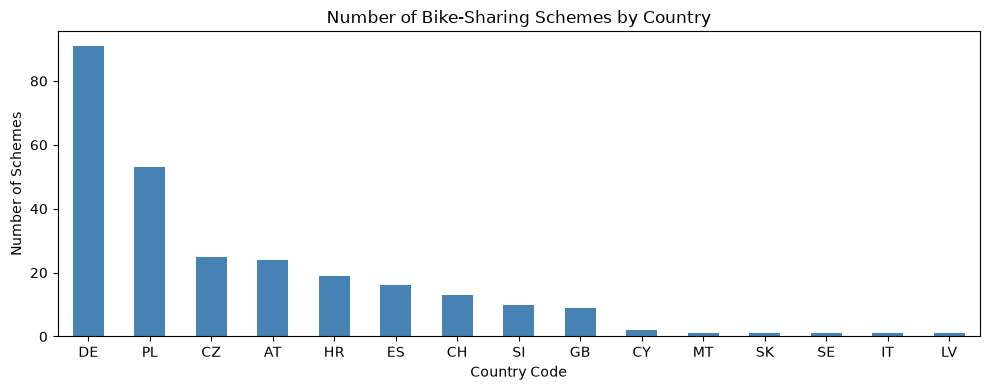

In [10]:
country_counts.plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.title("Number of Bike-Sharing Schemes by Country")
plt.xlabel("Country Code")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# Calculate the share of schemes in Germany and Poland together.
top_two_share = (country_counts["DE"] + country_counts["PL"]) / len(cities_clean) * 100
print("Germany and Poland together:", round(top_two_share, 1), "%")

Germany and Poland together: 53.9 %


**Result:** The data covers 15 countries. Germany has 91 schemes and Poland has 53.
Together they account for 53.9% of the table, so pooled comparisons will be strongly
influenced by these two countries.

### 5. Explore return rules

`True` means bikes must be returned to an official station. `False` means this particular
requirement does not apply; it does not mean the scheme has no stations.

In [12]:
return_counts = cities_clean["return_to_official_only"].value_counts()
return_counts

return_to_official_only
True     200
False     67
Name: count, dtype: int64

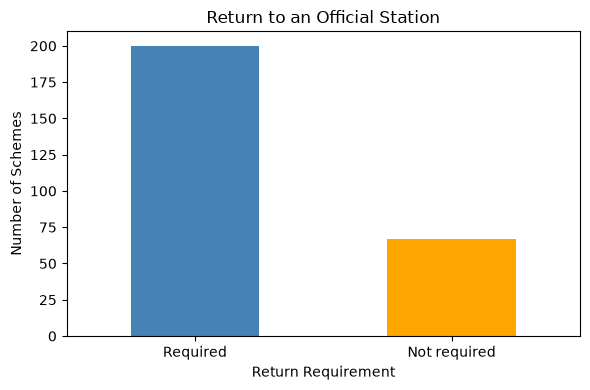

In [13]:
# Put the bars in a fixed order and give them readable labels.
return_counts = return_counts.reindex([True, False], fill_value=0)
return_counts.index = ["Required", "Not required"]

return_counts.plot(kind="bar", figsize=(6, 4), color=["steelblue", "orange"])
plt.title("Return to an Official Station")
plt.xlabel("Return Requirement")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
# A cross-tabulation counts combinations of two columns.
return_by_country = pd.crosstab(
    cities_clean["country"],
    cities_clean["return_to_official_only"]
)
return_by_country = return_by_country.rename(columns={True: "Required", False: "Not required"})
return_by_country

return_to_official_only,Not required,Required
country,,
AT,14,10
CH,2,11
CY,1,1
CZ,20,5
DE,22,69
ES,1,15
GB,0,9
HR,0,19
IT,0,1


**Result:** 200 schemes (74.9%) require official-station returns; 67 do not.
The cross-tabulation shows differences across countries, but the number of schemes
per country varies. This field will be useful when interpreting missing station IDs in trip data.

### 6. Explore locations

`describe()` summarizes the coordinates. The scatter plot shows approximate scheme centers.
It is a simple longitude/latitude plot, not a geographic map with distance-preserving axes.

In [15]:
cities_clean[["lat", "lon"]].describe()

,lat,lon
count,267.000000,267.000000
mean,49.067596,12.154192
std,4.155125,7.029840
min,27.815400,-15.518200
25%,47.827850,8.306550
50%,49.898000,13.744600
75%,51.589750,16.831200
max,57.690200,33.453500


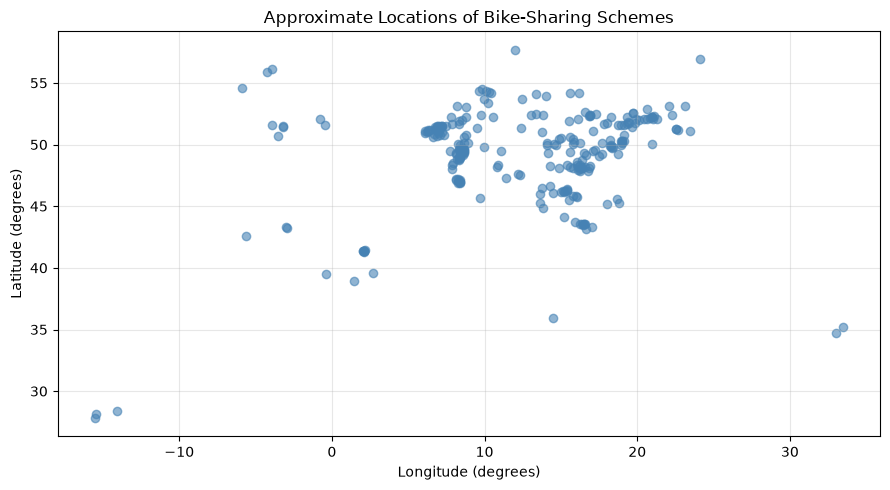

In [16]:
plt.figure(figsize=(9, 5))
plt.scatter(cities_clean["lon"], cities_clean["lat"], alpha=0.6, color="steelblue")
plt.title("Approximate Locations of Bike-Sharing Schemes")
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# keep=False marks every row in a group with shared coordinates.
shared_locations = cities_clean[
    cities_clean.duplicated(subset=["lat", "lon"], keep=False)
]
shared_locations[["id", "name", "country", "lat", "lon"]]

,id,name,country,lat,lon
35,251,Lublin,PL,51.2469,22.5697
241,729,Stacje Sponsorskie Nextbike LRM,PL,51.2469,22.5697


**Result:** Lublin and Stacje Sponsorskie Nextbike LRM share the same coordinates but have
different IDs. Both are kept because shared approximate centers do not prove duplicate schemes.
The Canary Islands explain the group of points southwest of most other records.

### 7. Explore timezone labels

Count the recorded timezone labels and compare them with country codes. A label naming
another country is a reason to inspect the metadata, not a reason to replace it automatically.

In [18]:
timezone_counts = cities_clean["timezone"].value_counts()
timezone_counts

timezone
Europe/Berlin        184
Europe/Warsaw         52
Europe/Brussels       14
Europe/London          9
Atlantic/Canary        3
Asia/Istanbul          2
Europe/Bratislava      1
Europe/Rome            1
Europe/Riga            1
Name: count, dtype: int64

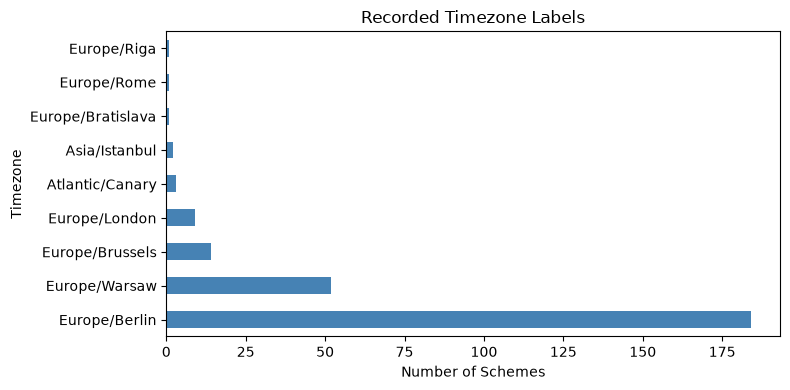

In [19]:
timezone_counts.plot(kind="barh", figsize=(8, 4), color="steelblue")
plt.title("Recorded Timezone Labels")
plt.xlabel("Number of Schemes")
plt.ylabel("Timezone")
plt.tight_layout()
plt.show()

In [20]:
pd.crosstab(cities_clean["country"], cities_clean["timezone"])

timezone,Asia/Istanbul,Atlantic/Canary,Europe/Berlin,Europe/Bratislava,Europe/Brussels,Europe/London,Europe/Riga,Europe/Rome,Europe/Warsaw
country,,,,,,,,,
AT,0,0,24,0,0,0,0,0,0
CH,0,0,0,0,13,0,0,0,0
CY,2,0,0,0,0,0,0,0,0
CZ,0,0,25,0,0,0,0,0,0
DE,0,0,90,0,0,0,0,1,0
ES,0,3,12,0,1,0,0,0,0
GB,0,0,0,0,0,9,0,0,0
HR,0,0,19,0,0,0,0,0,0
IT,0,0,1,0,0,0,0,0,0


**Result:** There are 9 timezone labels. `Europe/Berlin` appears in 184 records across
several countries. Check timezone suitability before using it to create local-hour features.
Do not replace timezone labels based only on their names or use one fixed UTC offset for all dates.

### 8. Save the cleaned data

Save to a new file so the raw CSV stays unchanged. The CSV contains data only;
when loading it again, pandas infers the column types.

In [21]:
output_folder = str(CLEAN_DIR)
os.makedirs(output_folder, exist_ok=True)

cities_clean.to_csv(output_folder + "/cities_clean.csv", index=False)
print("Cleaned data saved to data_cleaned/cities_clean.csv")
print("Final shape:", cities_clean.shape)

Cleaned data saved to data_cleaned/cities_clean.csv
Final shape: (267, 7)


### Main findings

- The table contains 267 schemes across 15 countries.
- No missing values or duplicate IDs were found. Two names needed whitespace cleaning.
- Germany and Poland account for 53.9% of the supplied schemes.
- 74.9% of schemes require a return to an official station.
- Two different scheme IDs share the same coordinates and are retained.
- Timezone labels need review before creating local-time features.
- This table describes schemes. Trip and station-status data are needed to study usage and demand.

# 2. Bikes and bike types (`bikes.csv`, `bike_types.csv`)

## Bike types: understanding, statistics, cleaning

This section is about the datasets bike_types and bikes (`bikes.csv` only has 3 columns, so it is analysed through its join with `bike_types`).

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "figure.dpi": 110,
})
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

In [23]:
bike_types = pd.read_csv(ROOT / "bike_types.csv")
bikes = pd.read_csv(ROOT / "bikes.csv")

print(bike_types.shape, bikes.shape)
bike_types.dtypes

(121, 9) (88436, 3)


id                    int64
vehicle_image           str
name                    str
description             str
form_factor             str
rider_capacity      float64
propulsion_type         str
max_range           float64
battery_capacity    float64
dtype: object

In [24]:
bike_types.sample(8, random_state=0)

,id,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
48,182,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,electric_assist,60000.0,500.0
94,240,https://static.nextbike.net/app/biketypes/type/bf/240/h5...,e-Cargobike,"DOLLY BIKES ""e-Dolly"" MaxDrive\r\n\r\n - BAFANG M400 250...",cargo_bicycle,1.0,electric_assist,NaN,NaN
95,241,https://static.nextbike.net/app/biketypes/type/bf/241/h5...,e-Cargobike,"DOLLY BIKES ""e-Dolly"" MaxDrive\r\n\r\n - BAFANG M400 250...",cargo_bicycle,1.0,electric_assist,NaN,600.0
8,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97,85,https://static.nextbike.net/app/biketypes/type/gt/85/h50...,ebike [električni bicikl],NaN,bicycle,1.0,electric_assist,60000.0,500.0
22,205,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,159,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1. Understanding the dataset


#### 1.1 Missing values

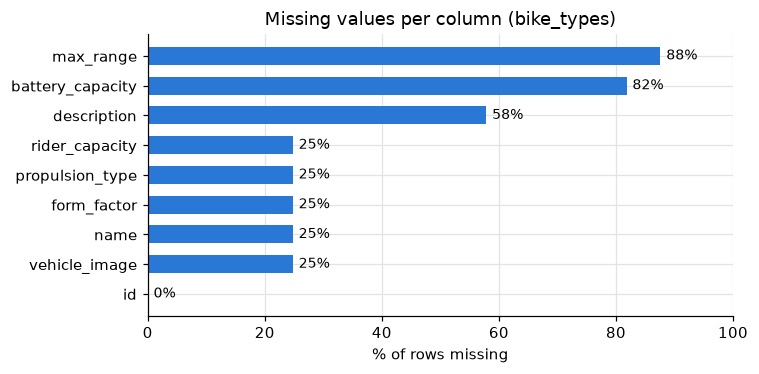

In [25]:
missing = bike_types.isna().mean().sort_values() * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(missing.index, missing.values, color=BLUE, height=0.6)
for y, v in enumerate(missing.values):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values per column (bike_types)")
plt.tight_layout()

In [26]:
attr_cols = bike_types.columns.drop("id")
empty = bike_types[attr_cols].isna().all(axis=1)
print(f"{empty.sum()} rows have only an id and nothing else")

30 rows have only an id and nothing else


A lot of bike types don't have a "battery_capacity" and a "max_range". We can assume that some cities don't have electric bikes, so it's normal to not have these two columns filled.
We have also 30 rows with only an id and nothing else. 5 variables are missing for 25% of the bike types, we can think that they come from the same export.

In [27]:
bikes_per_type = bikes["bike_type_id"].value_counts()
bike_types["n_bikes"] = bike_types["id"].map(bikes_per_type).fillna(0).astype(int)

print("bike types never used by any bike:", (bike_types["n_bikes"] == 0).sum())
print("bikes whose type is missing from bike_types:", (~bikes["bike_type_id"].isin(bike_types["id"])).sum())
print(f"bikes pointing to an empty type: {bike_types.loc[empty, 'n_bikes'].sum()} / {len(bikes)}")
bike_types.loc[empty, ["id", "n_bikes"]].sort_values("n_bikes", ascending=False).head(10)

bike types never used by any bike: 0
bikes whose type is missing from bike_types: 0
bikes pointing to an empty type: 1050 / 88436


,id,n_bikes
0,152,778
4,37,120
14,60,24
3,34,19
2,35,19
20,219,14
22,205,10
9,53,7
7,92,7
6,214,7


#### 1.2 Keys and the image URL

In [28]:
print("id unique:", bike_types["id"].is_unique)

# URL format: https://static.nextbike.net/app/biketypes/type/<system>/<id>/h500.png
url_parts = bike_types["vehicle_image"].str.split("/")
system_code = url_parts.str[-3]
url_id = pd.to_numeric(url_parts.str[-2])

print("URL id == id:", (url_id == bike_types["id"]).sum(), "/", bike_types["vehicle_image"].notna().sum())
print("distinct system codes in URLs:", system_code.nunique())
system_code.value_counts().head(10)

id unique: True
URL id == id: 91 / 91
distinct system codes in URLs: 50


vehicle_image
pr    6
bf    5
dl    4
pd    3
bp    3
ur    3
pv    3
gt    3
gp    2
lv    2
Name: count, dtype: int64

We can see that all ids are unique, so it's great. 
Inside the url, there is a system code is the type of bike that belongs to a city or a network. The same bikes can appear in different cities but the system is different.

### 2. Descriptive statistics

In [29]:
for col in ["form_factor", "propulsion_type", "rider_capacity"]:
    print(bike_types[col].value_counts(dropna=False), "\n")

form_factor
bicycle          71
NaN              30
cargo_bicycle    19
other             1
Name: count, dtype: int64 

propulsion_type
human              64
NaN                30
electric_assist    27
Name: count, dtype: int64 

rider_capacity
1.0    70
NaN    30
2.0    21
Name: count, dtype: int64 



In [30]:
pd.crosstab(bike_types["form_factor"], [bike_types["propulsion_type"], bike_types["rider_capacity"]], dropna=False)

propulsion_type electric_assist         human         nan        
rider_capacity              1.0 2.0 NaN   1.0 2.0 NaN 1.0 2.0 NaN
form_factor                                                      
bicycle                      15   0   0    35  21   0   0   0   0
cargo_bicycle                12   0   0     7   0   0   0   0   0
other                         0   0   0     1   0   0   0   0   0
NaN                           0   0   0     0   0   0   0   0  30

We can observe that there are 64 non-electric bike types and 27 electric bike types. 70 carry just one person and 21 can carry two people. 
30 are NaN but they come from the 30 lines that are just filled with an id.

#### 2.1 Counting types vs counting bikes


,% of types,% of bikes
other / human,0.8,0.0
cargo_bicycle / electric_assist,9.9,0.1
cargo_bicycle / human,5.8,0.2
unknown / unknown,24.8,1.2
bicycle / electric_assist,12.4,6.5
bicycle / human,46.3,92.0


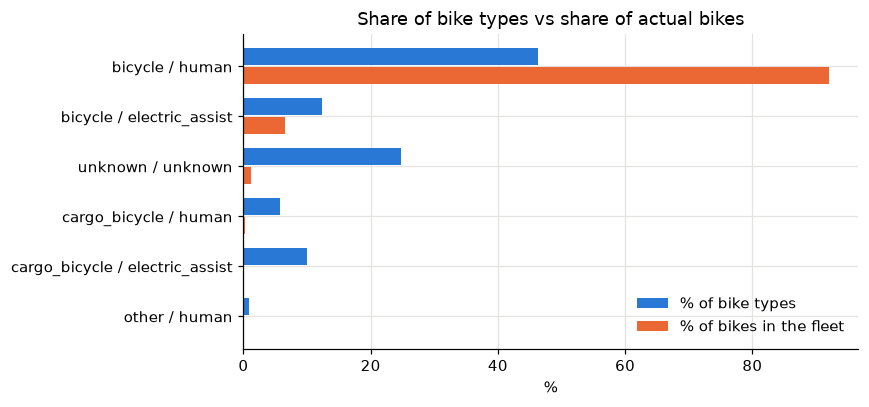

In [31]:
group = (
    bike_types["form_factor"].fillna("unknown") + " / " + bike_types["propulsion_type"].fillna("unknown")
)
share = pd.DataFrame({
    "% of types": group.value_counts(normalize=True) * 100,
    "% of bikes": bike_types.groupby(group)["n_bikes"].sum() / bike_types["n_bikes"].sum() * 100,
}).sort_values("% of bikes")

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(share))
h = 0.38
ax.barh(y + h / 2, share["% of types"], height=h - 0.04, color=BLUE, label="% of bike types")
ax.barh(y - h / 2, share["% of bikes"], height=h - 0.04, color=ORANGE, label="% of bikes in the fleet")
ax.set_yticks(y, share.index)
ax.set_xlabel("%")
ax.set_title("Share of bike types vs share of actual bikes")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
share.round(1)

In this section we compare the two datasets "bike_types.csv" and "bikes.csv". 
We compare the number of bikes for each type and not just the types. For instance we saw before that there were 64 non-electric bikes vs 27 electric bikes. Electric bikes represent 30% of the bike types (excluding the NaN). But if we observe the number of bikes for each type, electric bikes represent just 7%, the vast majority are non-electric bikes. 
The same thing applies for cargo bikes. They represent 21% of the bike types (excluding the NaN) but just 0.3% of the bikes available.

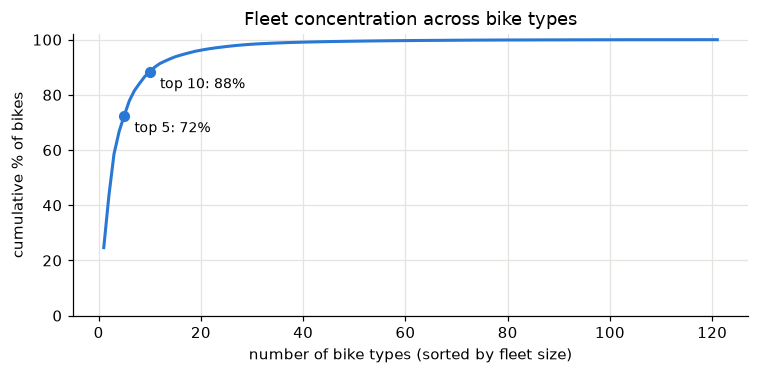

In [32]:
sorted_bikes = bike_types["n_bikes"].sort_values(ascending=False).to_numpy()
cum_share = sorted_bikes.cumsum() / sorted_bikes.sum() * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, len(cum_share) + 1), cum_share, color=BLUE, lw=2)
for k in (5, 10):
    ax.scatter(k, cum_share[k - 1], color=BLUE, s=40, zorder=3)
    ax.text(k + 2, cum_share[k - 1] - 6, f"top {k}: {cum_share[k - 1]:.0f}%", fontsize=9)
ax.set_xlabel("number of bike types (sorted by fleet size)")
ax.set_ylabel("cumulative % of bikes")
ax.set_ylim(0, 102)
ax.set_title("Fleet concentration across bike types")
plt.tight_layout()

With this feature and graph we can observe that just 5 types cover 72% of the bikes and 10 types cover 88%. The rest (more than 100 other types) cover less than 12% of the bikes.

In [33]:
bike_types.sort_values("n_bikes", ascending=False)[
    ["id", "name", "form_factor", "propulsion_type", "rider_capacity", "battery_capacity", "n_bikes"]
].head(10)

,id,name,form_factor,propulsion_type,rider_capacity,battery_capacity,n_bikes
119,150,with Framelock,bicycle,human,1.0,NaN,21791
118,196,with Framelock,bicycle,human,1.0,NaN,16604
111,71,SMARTbike 2.0 (A) 2018,bicycle,human,1.0,NaN,13375
112,15,with Fork lock,bicycle,human,1.0,NaN,7227
108,4,CLASSICbike,bicycle,human,1.0,NaN,5108
24,174,Comfort,bicycle,human,1.0,NaN,4756
90,192,with Framelock,bicycle,human,1.0,NaN,3258
107,204,E-Bike,bicycle,electric_assist,1.0,500.0,2309
120,198,3-rychlostní SMARTbike 2.0.,bicycle,human,1.0,NaN,2165
113,14,Comfort 1 1/8 Zoll,bicycle,human,1.0,NaN,1607


If we print the types with the most bikes we observe that some models are represented in several cities like the "framelock", the "comfort" or "SMARTbike 2.0". Also the "Framelock" is the most represented bike in the dataset. 

#### 2.2 Electric bikes: range and battery

In [34]:
electric = bike_types[bike_types["propulsion_type"] == "electric_assist"]
print("electric types:", len(electric))
print("max_range values:", electric["max_range"].value_counts(dropna=False).to_dict())
print("battery_capacity values:", electric["battery_capacity"].value_counts(dropna=False).to_dict())
print("human types with a battery or range:", bike_types.loc[bike_types["propulsion_type"] == "human", ["max_range", "battery_capacity"]].notna().any(axis=1).sum())

electric types: 27
max_range values: {60000.0: 15, nan: 12}
battery_capacity values: {500.0: 13, 600.0: 6, nan: 5, 630.0: 2, 690.0: 1}
human types with a battery or range: 0


Regarding the range of the electric bikes, there is just one value "60000.0" so 60 km. But the value of the battery capacity differs from one bike to another. We can assume that "60000.0" is a default value and doesn't represent something true. 
Regarding the battery capacity, we notice 4 different batteries.

#### 2.3 Names and descriptions

In [35]:
bike_types["name"].value_counts().head(15)

name
Rower z fotelikiem dziecięcym    10
Tandem                            7
e-Cargobike                       7
e-CARGObike                       5
Rowerek dziecięcy 6+              5
E-Bike                            4
with Framelock                    4
Cargo                             4
3-rychlostní SMARTbike 2.0.       3
e-SMARTbike 2.0.                  3
7-rychlostní SMARTbike            2
CARGObike                         2
8-rychlostní SMARTbike            2
Comfort                           1
Elektricno kolo                   1
Name: count, dtype: int64

If we count how many types have the same name, we observe that several models of bikes are present in multiple cities or networks. For instance the model "Rower z fotelikiem dziecięcym" is present in 10 cities or networks. The name is the same, so it's probably cities in the same country or link to the same company that own the bikes.

In [36]:
print("types with a description:", bike_types["description"].notna().sum())
print(bike_types.loc[bike_types["description"].notna(), "description"].iloc[0])

types with a description: 51
- MountainBike Rahmen ALU
- Shimano 27-Gang-Schaltung
- RST-Federgabel
- Gepäckträger 


#### 2.4 Cross-check with trips: does `propulsion_type` match the battery data?


In [37]:
trips = pd.read_csv(ROOT / "trips_small.csv", usecols=["bike_id", "battery_start"])
trips = trips.merge(bikes[["id", "bike_type_id"]], left_on="bike_id", right_on="id", how="left")
trips = trips.merge(
    bike_types[["id", "propulsion_type"]].rename(columns={"id": "bike_type_id"}),
    on="bike_type_id", how="left",
)
trips["has_battery"] = trips["battery_start"].notna()

pd.crosstab(trips["propulsion_type"].fillna("unknown (empty type)"), trips["has_battery"], margins=True)

has_battery,False,True,All
propulsion_type,,,
electric_assist,11861,168230,180091
human,978637,302,978939
unknown (empty type),2346,0,2346
All,992844,168532,1161376


Electric bikes have a battery level in 93% of their trips. Human bikes almost never do (302 out of 979,000 trips, about 0.03%, probably sensor errors).
The variable "propulsion_type" can be trusted. The 2,346 trips made with bikes of an empty type never have a battery level, so these bikes are very likely normal bikes. 

In [38]:
battery_evidence = trips.groupby("bike_type_id").agg(
    n_trips=("has_battery", "size"),
    battery_share=("has_battery", "mean"),
)
battery_evidence.loc[battery_evidence.index.isin(bike_types.loc[empty, "id"])].sort_values("n_trips", ascending=False)

,n_trips,battery_share
bike_type_id,,
152,1468,0.0
60,179,0.0
205,168,0.0
219,144,0.0
218,97,0.0
72,59,0.0
53,56,0.0
149,44,0.0
17,32,0.0


30 bike types have no information. We don't know if they are electric or normal bikes. We look at their trips. Electric bikes report a battery level, normal bikes don't. If a type's trips never show a battery, it's probably a normal bike. We added a threshold to make sure that a bike with just 1 trip doesn't count. The threshold is 30.

### 3. Cleaning

1. We keep the 30 empty rows. They have no information, but 1,050 real bikes use them. If we delete them, those bikes lose their type when we join the tables.
2. We remove 3 columns : "max_range", "vehicle_image" and "description". 
"max_range" is always 60km so it's not information.
"vehicle_image" is just a URL, we keep the system code and drop the rest that is not bringing information.
"description" is free text in many languages, and missing 58% of the time. We just keep a column that says yes/no description
3. We fill the empty types with information from the experiments with the trips. 
4. We treat missing battery values in 2 different ways.
human bikes : no battery we put 0
electric bikes : battery exist but the value is NaN = we put the median (500 Wh)
5. We replace missing text values with "unknown". "form_factor", "propulsion_type" and "name" get "unknown" instead of NaN. This way, "unknown" becomes a real category we can count and plot.
6. We add new useful columns :
- n_bikes: how many real bikes have this type
- system_code: the bike-sharing system, taken from the URL
- is_electric, is_cargo: simple yes/no columns, easy to use later
- name_group: groups the many names in different languages into a few categories (standard, child seat, tandem, cargo, kids bike, handbike, unknown)
- is_empty_type: marks the 30 rows that were empty


In [39]:
clean = bike_types.copy()

clean["system_code"] = system_code
clean["has_description"] = clean["description"].notna()
clean = clean.drop(columns=["vehicle_image", "description", "max_range"])

clean["is_empty_type"] = empty
MIN_TRIPS = 30
battery_share = clean["id"].map(battery_evidence["battery_share"])
n_trips = clean["id"].map(battery_evidence["n_trips"])
human_by_trips = empty & (battery_share == 0) & (n_trips >= MIN_TRIPS)
clean.loc[human_by_trips, "propulsion_type"] = "human"
clean["propulsion_imputed"] = human_by_trips

clean["form_factor"] = clean["form_factor"].fillna("unknown")
clean["propulsion_type"] = clean["propulsion_type"].fillna("unknown")
clean["name"] = clean["name"].fillna("Unknown")

is_electric = clean["propulsion_type"] == "electric_assist"
battery_median = clean.loc[is_electric, "battery_capacity"].median()
clean["battery_imputed"] = is_electric & clean["battery_capacity"].isna()
clean.loc[clean["battery_imputed"], "battery_capacity"] = battery_median
clean.loc[clean["propulsion_type"] == "human", "battery_capacity"] = 0

clean["is_electric"] = is_electric
clean["is_cargo"] = clean["form_factor"] == "cargo_bicycle"

In [40]:
def name_group(name):
    name = name.lower()
    if name == "unknown":
        return "unknown"
    if "fotelik" in name or "child" in name or "sjedalica" in name:
        return "child_seat"
    if "rowerek" in name or "kinderfahrrad" in name:
        return "kids_bike"
    if "tandem" in name:
        return "tandem"
    if "cargo" in name or "trójkołowy" in name:
        return "cargo"
    if "handbike" in name:
        return "handbike"
    return "standard"

clean["name_group"] = clean["name"].apply(name_group)

clean["name_group"].value_counts()

name_group
standard      42
unknown       31
cargo         20
child_seat    13
tandem         7
kids_bike      7
handbike       1
Name: count, dtype: int64

In [41]:
for col in ["form_factor", "propulsion_type", "name_group", "system_code"]:
    clean[col] = clean[col].astype("category")
clean.isna().sum()

id                     0
name                   0
form_factor            0
rider_capacity        30
propulsion_type        0
battery_capacity      21
n_bikes                0
system_code           30
has_description        0
is_empty_type          0
propulsion_imputed     0
battery_imputed        0
is_electric            0
is_cargo               0
name_group             0
dtype: int64

In [42]:
assert clean["id"].is_unique
assert bikes["bike_type_id"].isin(clean["id"]).all()
assert (clean.loc[clean["is_electric"], "battery_capacity"] > 0).all()

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
clean.to_parquet(CLEAN_DIR / "bike_types.parquet", index=False)
clean.to_csv(CLEAN_DIR / "bike_types.csv", index=False)
clean.head()

,id,name,form_factor,rider_capacity,propulsion_type,battery_capacity,n_bikes,system_code,has_description,is_empty_type,propulsion_imputed,battery_imputed,is_electric,is_cargo,name_group
0,152,Unknown,unknown,NaN,human,0.0,778,NaN,False,True,True,False,False,False,unknown
1,31,Unknown,unknown,NaN,unknown,NaN,2,NaN,False,True,False,False,False,False,unknown
2,35,Unknown,unknown,NaN,unknown,NaN,19,NaN,False,True,False,False,False,False,unknown
3,34,Unknown,unknown,NaN,unknown,NaN,19,NaN,False,True,False,False,False,False,unknown
4,37,Unknown,unknown,NaN,unknown,NaN,120,NaN,False,True,False,False,False,False,unknown


# 3. Stations (`stations.csv`)

## Exploration Preprocessing of stations data 

### Importing dependencises

Overview: This notebook covers the data cleaning, validation, and spatial preprocessing steps for the station dataset.

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import contextily as cx
from matplotlib.colors import LinearSegmentedColormap

plt.rcdefaults()  # start from matplotlib defaults, as in the original stations notebook


In [44]:
# Set global seaborn style - clean background without grid
sns.set_style("white", {
    "axes.grid": False,           # Remove grid lines
    "axes.spines.left": True,     # Keep left spine
    "axes.spines.bottom": True,   # Keep bottom spine
    "axes.spines.top": False,     # Remove top spine
    "axes.spines.right": False,   # Remove right spine
    "axes.linewidth": 1.2,        # Slightly thicker axis lines
})

# Set inclusive and colorblind-friendly palette
# Using 'colorblind' palette which is accessible to colorblind users
sns.set_palette("colorblind")

### Data Exploration

In [45]:
df_stations=pd.read_csv(ROOT / "stations.csv")
dim=df_stations.shape
print(dim)
print((df_stations).info())


(2932, 11)
<class 'pandas.DataFrame'>
RangeIndex: 2932 entries, 0 to 2931
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2932 non-null   int64  
 1   city_id        2932 non-null   int64  
 2   name           2932 non-null   str    
 3   app_number     2932 non-null   int64  
 4   terminal_type  2345 non-null   str    
 5   place_type     2932 non-null   int64  
 6   bike_racks     2932 non-null   int64  
 7   special_racks  2932 non-null   int64  
 8   rack_locks     0 non-null      float64
 9   lon            2932 non-null   float64
 10  lat            2932 non-null   float64
dtypes: float64(3), int64(6), str(2)
memory usage: 326.9 KB
None


In [46]:
df_stations.describe()

,id,city_id,app_number,place_type,bike_racks,special_racks,rack_locks,lon,lat
count,2.932000e+03,2932.000000,2932.000000,2932.000000,2932.000000,2932.000000,0.0,2932.000000,2932.000000
mean,4.116020e+07,480.171555,29985.929400,3.760914,6.033424,-0.011255,NaN,13.172182,49.272772
std,4.773764e+07,242.781001,61868.290176,6.894175,6.495116,0.486820,NaN,6.914270,4.342509
min,9.400000e+01,7.000000,0.000000,0.000000,0.000000,-10.000000,NaN,-15.758277,7.745476
25%,3.604443e+06,251.000000,4918.750000,0.000000,0.000000,0.000000,NaN,8.156823,47.955417
50%,2.531790e+07,527.000000,7907.500000,0.000000,6.000000,0.000000,NaN,14.314387,50.290478
75%,5.661078e+07,702.000000,48798.250000,0.000000,10.000000,0.000000,NaN,17.488668,51.602447
max,2.192360e+08,858.000000,999574.000000,27.000000,70.000000,12.000000,NaN,33.413632,57.005195


#### missing values

In [47]:
def check_miss(df):  
    dim=df.shape
    n_miss = df.shape[0]-df.count()
    p_miss = (n_miss/dim[0])*100
    s_type = df.dtypes 
    n_values = df.nunique(dropna=True) 
    miss_df=pd.DataFrame()
    miss_df["n_missing"]=n_miss
    miss_df["p_missing"]=p_miss
    miss_df["feat_type"]=s_type
    miss_df["nu_unique"]=n_values
    return miss_df


In [48]:
display(check_miss(df_stations))

,n_missing,p_missing,feat_type,nu_unique
id,0,0.000000,int64,2932
city_id,0,0.000000,int64,185
name,0,0.000000,str,2855
app_number,0,0.000000,int64,2914
terminal_type,587,20.020464,str,10
place_type,0,0.000000,int64,16
bike_racks,0,0.000000,int64,33
special_racks,0,0.000000,int64,11
rack_locks,2932,100.000000,float64,0
lon,0,0.000000,float64,2912


we can see clearly that all the value of `rack_locks` column are missing making removing it the best choice for our cleaning process
`name`,`app_number` are dropped likewise, the columns were dropped as they provide no analytical value and are not used as a join key with any other dataset.

In [49]:
cleaned_df=df_stations.drop(["rack_locks","name","app_number"],axis=1)
display(check_miss(cleaned_df))


,n_missing,p_missing,feat_type,nu_unique
id,0,0.000000,int64,2932
city_id,0,0.000000,int64,185
terminal_type,587,20.020464,str,10
place_type,0,0.000000,int64,16
bike_racks,0,0.000000,int64,33
special_racks,0,0.000000,int64,11
lon,0,0.000000,float64,2912
lat,0,0.000000,float64,2911


#### Dealing with terminal type feature 

terminal_type feature  has more than 20% missing values with 10 unique values missing two types, (compared to the 12 expected types outlined in the dataset description in the challenge document).
for that missing entries are explicitly imputed with the string "Missing" to retain structural records without biasing distribution metrics.


<Axes: xlabel='terminal_type'>

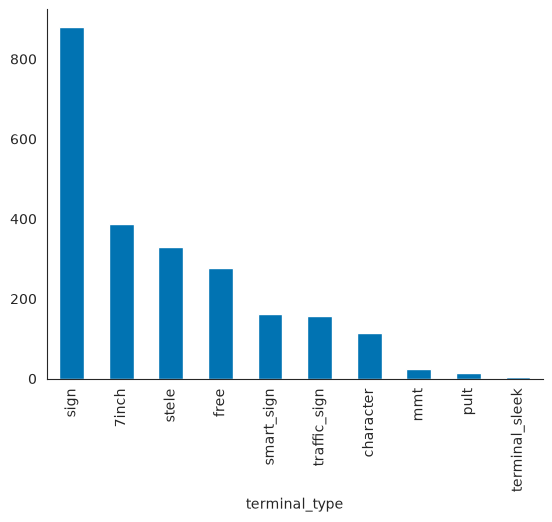

In [50]:
((cleaned_df.terminal_type.value_counts())).plot(kind="bar")


In [51]:
cleaned_df.terminal_type=cleaned_df.terminal_type.fillna("Missing")
cleaned_df

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
0,142186362,135,Missing,12,0,0,7.821669,51.677449
1,940986,176,Missing,0,6,0,13.868973,54.090538
2,93646685,176,stele,0,15,0,13.918970,54.073088
3,111365509,243,smart_sign,0,20,0,-3.936120,56.119272
4,405835,302,sign,0,6,0,14.481456,35.906836
...,...,...,...,...,...,...,...,...
2927,294352,128,Missing,0,11,0,24.156725,57.005195
2928,20729102,527,7inch,0,10,0,21.249210,52.121370
2929,9575430,530,Missing,0,9,0,6.440451,51.163646
2930,18599421,675,7inch,14,4,0,-13.864890,28.384953


#### duplicated values


In [52]:
print("the number of duplicated values are :",cleaned_df.duplicated().sum())
print("the number of duplicated values are :",cleaned_df.duplicated().sum())


the number of duplicated values are : 0
the number of duplicated values are : 0


#### Data Validation

in this section we will to check the validity of the data in case of odd values

In [53]:
print("number of false values in bike_racks", (cleaned_df.bike_racks<0).sum() ," \n values", cleaned_df.iloc[cleaned_df.bike_racks<0])
print("number of false values in special_racks", (cleaned_df.special_racks<0).sum()," \n values \n ", cleaned_df.iloc[cleaned_df.special_racks<0].to_string())
neg_points= cleaned_df.iloc[cleaned_df.special_racks<0]
neg_ids=neg_points.id


number of false values in bike_racks 0  
 values Empty DataFrame
Columns: [id, city_id, terminal_type, place_type, bike_racks, special_racks, lon, lat]
Index: []
number of false values in special_racks 32  
 values 
               id  city_id terminal_type  place_type  bike_racks  special_racks        lon        lat
455    19772006      643         7inch          14           6             -2  15.382405  46.380096
974    21257660      220         7inch          14           6             -2  16.043296  45.818237
982    60833931      220         7inch          14          10             -4  16.012638  45.796928
1202   16852569      327         7inch          14           2             -1  15.235639  44.104679
1311   40538270      415         7inch          14          10             -4  16.048545  45.718726
1326    3561904      429         7inch          14          20            -10  13.595022  45.214403
1329    3562085      429         7inch          14          10             -5  13.

we can see that all negative value have  the same place type and same terminal type

Negative values observed in special_racks share identical `place_type` and `terminal_type` attributes, suggesting a systematic data recording error.

To cross-examine these invalid entries, we evaluate status snapshots from `stations_status.csv` to compare observed historical maximum capacities against reported values.

In [54]:
stat_s=pd.read_csv(ROOT / "stations_status.csv")

<Axes: xlabel='id'>

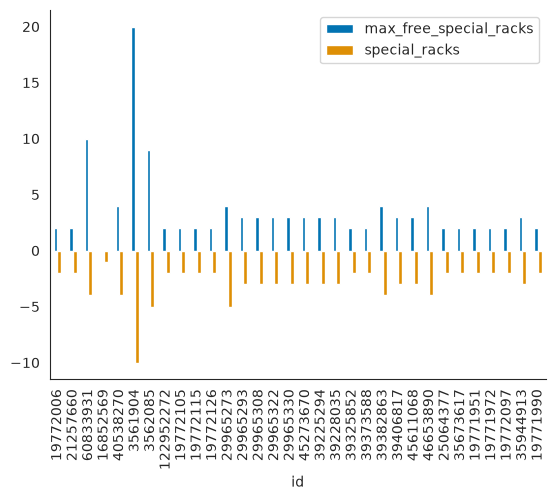

In [55]:

stat_s=stat_s.loc[stat_s.maintenance == False]
grouped_by_id=stat_s[["station_id","free_special_racks"]].groupby("station_id",as_index=False).max()
grouped_by_id.columns=["id","max_free_special_racks"]

join= grouped_by_id.merge(cleaned_df[["id","special_racks"]],on="id")
join.index=join.id
join[["max_free_special_racks","special_racks"]].loc[neg_ids].plot.bar(rot=90)

we can see that some values are not the same so the best choice is to remove the row with negativve values and keep them in seprated , givn the possibility that time time of count in stations.csv may differe than the max of stations.status.csv we choose not to consider in our anlaysis but impute them for our machine learning algorithms

In [56]:
removed_values=cleaned_df.iloc[cleaned_df.special_racks<0]
cleaned_df=cleaned_df.iloc[~cleaned_df.special_racks<0]

/tmp/ipykernel_591800/1929283515.py:14: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


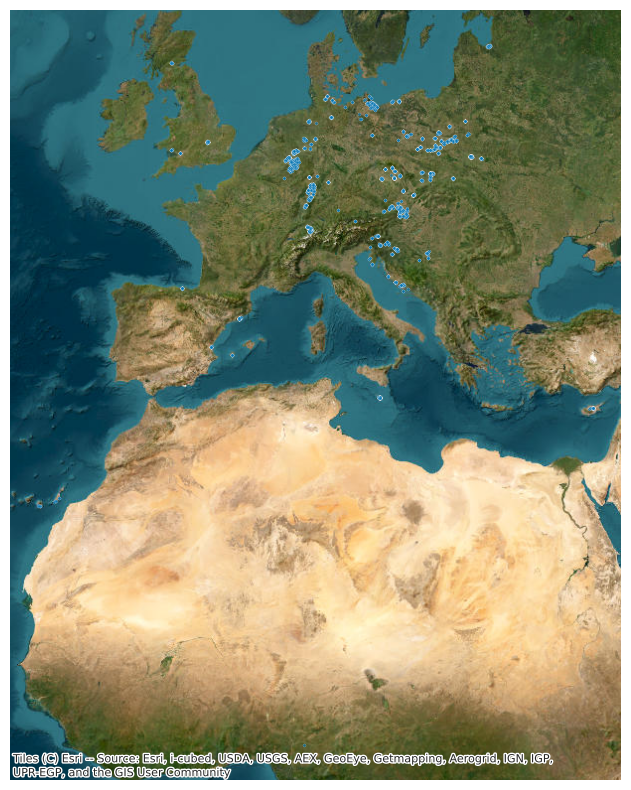

In [57]:
gdf = gpd.GeoDataFrame(
    cleaned_df,
    geometry=gpd.points_from_xy(cleaned_df.lon, cleaned_df.lat),
    crs="EPSG:4326",
)

gdf_wm = gdf.to_crs(epsg=3857)

gdf_wm["x"] = gdf_wm.geometry.x
gdf_wm["y"] = gdf_wm.geometry.y

fig, ax = plt.subplots(figsize=(10, 10))

sns.scatterplot(
    data=gdf_wm,
    x="x",
    y="y",
    s=5,           
    alpha=0.6,
    palette="viridis",
    ax=ax,
)

ax.set_aspect("equal")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)

ax.set_axis_off()
plt.show()

We can see some geospatial outliers Coordinates are evaluated against geographic bounding constraints for Europe ($\text{Latitude} \in [34^\circ, 71^\circ]$, $\text{Longitude} \in [-25^\circ, 60^\circ]$). points Outside these regions is either european small isolated territories  or utterly  falling outside european soil.

In [58]:
filter_lat=(~cleaned_df.lat.between(34,71))
filter_lon=(~cleaned_df.lon.between(-25,60))
filter_out=filter_lat | filter_lon
points_outside=cleaned_df.loc[filter_out]
points_outside

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
1658,18598248,638,7inch,14,4,0,-15.758277,27.824618
1659,18598681,638,7inch,14,4,0,-15.579987,27.762925
1660,18599537,638,7inch,14,6,0,-15.605667,27.742972
1661,18599596,638,7inch,14,6,0,-15.600083,27.740583
1662,18599750,638,7inch,14,4,0,-15.572444,27.756972
1663,18599772,638,7inch,14,4,0,-15.709750,27.781222
1664,18599901,638,7inch,14,6,0,-15.649778,27.782611
1665,18599488,675,7inch,14,4,0,-13.863219,28.390124
1666,18599628,675,7inch,14,6,0,-14.233111,28.150222
2486,205113328,858,free,0,0,0,7.801357,7.745476


/tmp/ipykernel_591800/2485667503.py:14: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


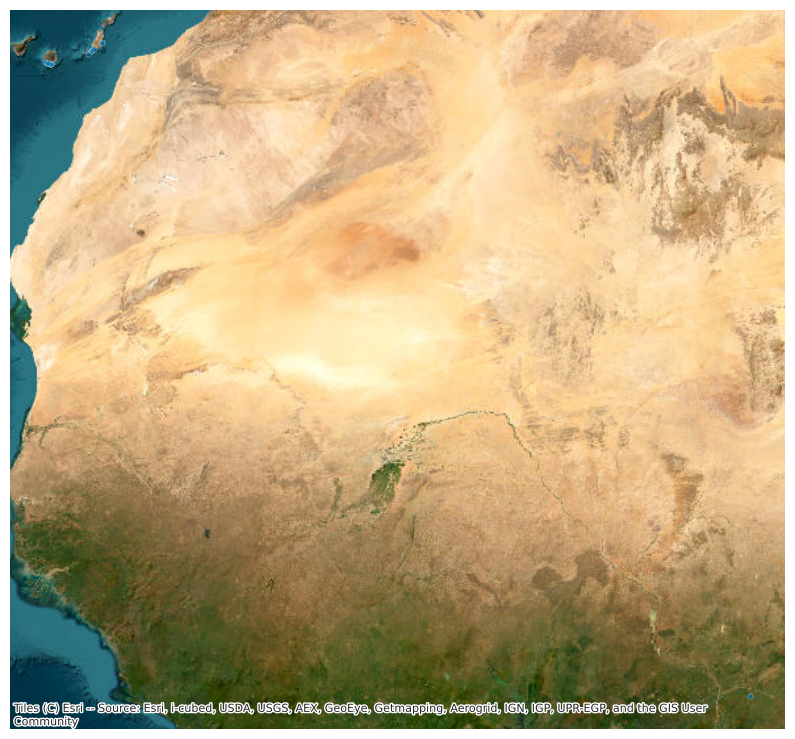

In [59]:
gdf = gpd.GeoDataFrame(
    points_outside,
    geometry=gpd.points_from_xy(points_outside.lon, points_outside.lat),
    crs="EPSG:4326",
)

gdf_wm = gdf.to_crs(epsg=3857)

gdf_wm["x"] = gdf_wm.geometry.x
gdf_wm["y"] = gdf_wm.geometry.y

fig, ax = plt.subplots(figsize=(10, 10))

sns.scatterplot(
    data=gdf_wm,
    x="x",
    y="y",
    s=15,             
    alpha=0.6,
    palette="viridis",
    ax=ax,
)

ax.set_aspect("equal")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)

ax.set_axis_off()
plt.show()

we can see clearly that these stations except the ones in canary islands are not in europe. 

In [60]:
canary_island_cityids=(638,675)
filter_cis=~((cleaned_df.city_id == canary_island_cityids[0]) | (cleaned_df.city_id == canary_island_cityids[1]))
new_filter = filter_cis & filter_out
cleaned_df.iloc[new_filter]

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
2486,205113328,858,free,0,0,0,7.801357,7.745476


after checking the station id in bike_types we determined the correct values which  are 
7.803989,52.188201

In [61]:
cleaned_df.loc[new_filter,"lat"] = 52.188201
cleaned_df.loc[new_filter,"lon"] = 7.803989
cleaned_df[new_filter]

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
2486,205113328,858,free,0,0,0,7.803989,52.188201


/tmp/ipykernel_591800/2665358396.py:14: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


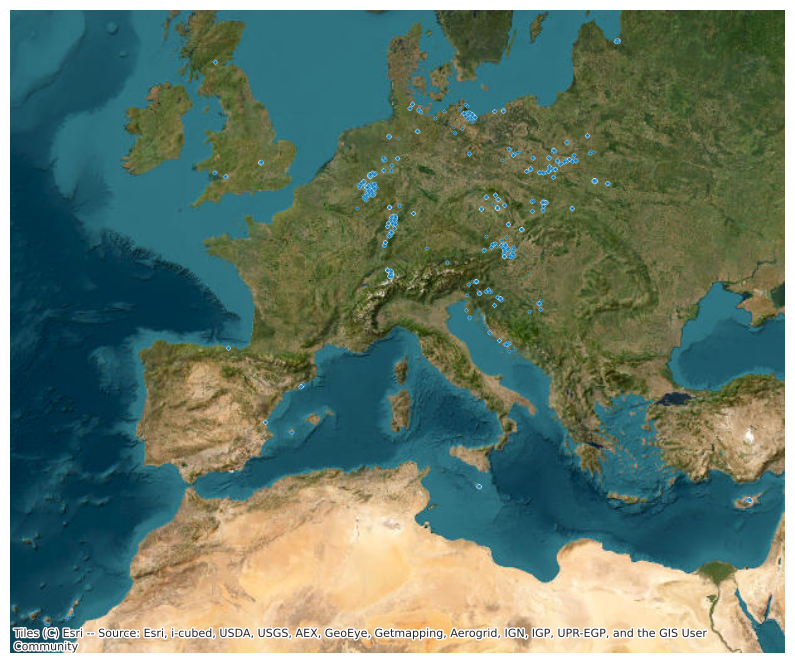

In [62]:
gdf = gpd.GeoDataFrame(
    cleaned_df,
    geometry=gpd.points_from_xy(cleaned_df.lon, cleaned_df.lat),
    crs="EPSG:4326",
)

gdf_wm = gdf.to_crs(epsg=3857)

gdf_wm["x"] = gdf_wm.geometry.x
gdf_wm["y"] = gdf_wm.geometry.y

fig, ax = plt.subplots(figsize=(10, 10))

sns.scatterplot(
    data=gdf_wm,
    x="x",
    y="y",
    s=5,            
    alpha=0.6,
    palette="viridis",
    ax=ax,
)

ax.set_aspect("equal")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)

ax.set_axis_off()
plt.show()

## Statistical analysis

In [63]:
matrix_correlation = cleaned_df.drop(["terminal_type","id","city_id"],axis=1).corr()
matrix_correlation

,place_type,bike_racks,special_racks,lon,lat
place_type,1.000000,-0.182787,0.083849,-0.354395,-0.057479
bike_racks,-0.182787,1.000000,0.012018,0.180057,0.167060
special_racks,0.083849,0.012018,1.000000,-0.007656,-0.006036
lon,-0.354395,0.180057,-0.007656,1.000000,-0.002151
lat,-0.057479,0.167060,-0.006036,-0.002151,1.000000


In [64]:
import folium
from folium.plugins import HeatMap
import pandas as pd

df_clean = cleaned_df.dropna(subset=['lat', 'lon'])

heat_data = df_clean[['lat', 'lon']].values.tolist()

center_lat = df_clean['lat'].mean()
center_lon = df_clean['lon'].mean()

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=11, 
    tiles="OpenStreetMap"
)

HeatMap(
    data=heat_data,
    radius=15,
    blur=10,
    min_opacity=0.4
).add_to(m)

m.save(str(ROOT / "assets" / "carte_robuste.html"))
print(f"Map generated with {len(heat_data)} points. Open the file 'assets/carte_robuste.html' in your browser.")


Map generated with 2900 points. Open the file 'assets/carte_robuste.html' in your browser.


![img](../assets/Screenshot%202026-10-16%20172624.png)

<Axes: xlabel='bike_racks'>

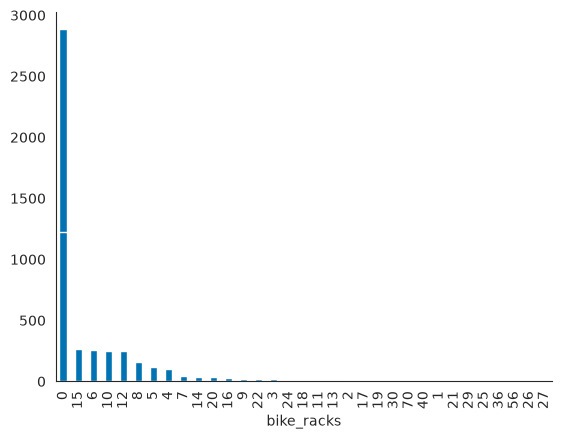

In [65]:
((cleaned_df.special_racks.value_counts())).plot.bar()
((cleaned_df.bike_racks.value_counts())).plot.bar()



<Axes: xlabel='terminal_type'>

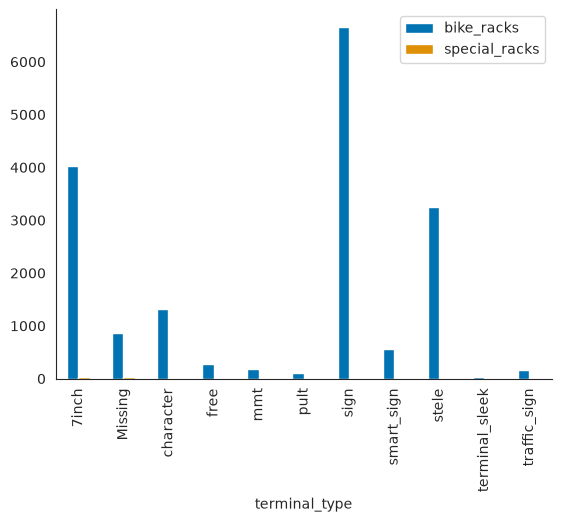

In [66]:

n_rack_pert=cleaned_df[["terminal_type","bike_racks","special_racks"]].groupby("terminal_type").sum()
n_rack_pert.plot.bar(rot=90)

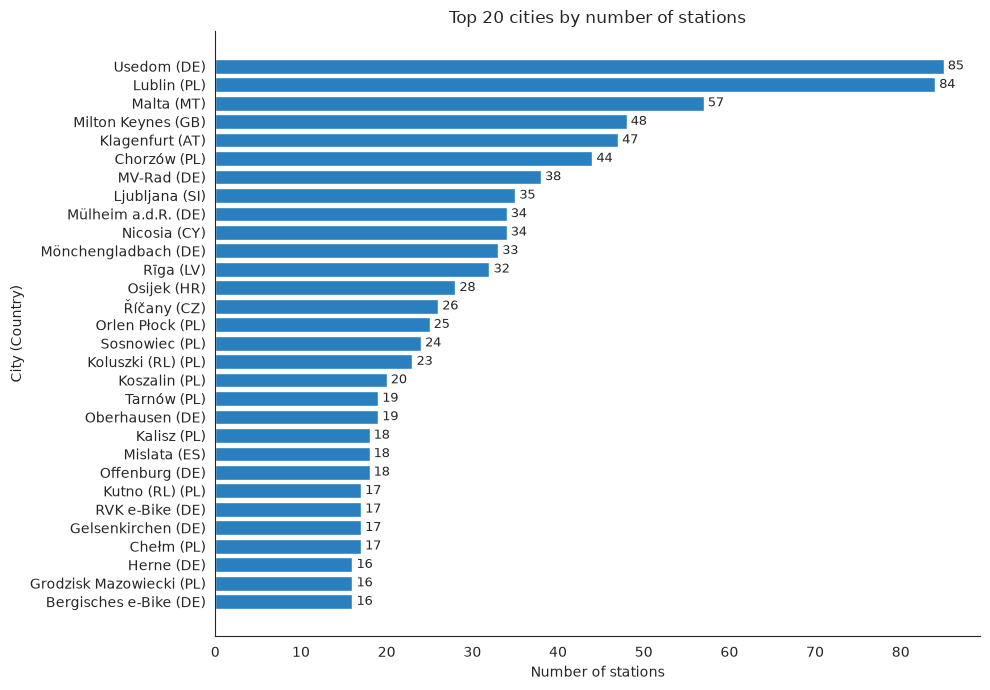

In [67]:
cities = pd.read_csv(ROOT / "cities.csv")   
info = cities.set_index('id')

df_st = cleaned_df[cleaned_df['bike_racks'] > 0]
top = df_st['city_id'].value_counts().head(30)      

labels = [
    f"{info.at[i, 'name']} ({info.at[i, 'country']})" if i in info.index else str(i)
    for i in top.index
]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(labels, top.values, color='#2a7fbf')
ax.invert_yaxis()                                   
ax.bar_label(bars, padding=3, fontsize=9)

ax.set_title('Top 20 cities by number of stations')
ax.set_xlabel('Number of stations')
ax.set_ylabel('City (Country)')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(ROOT / "assets" / "top20_cities.png", dpi=150)
plt.show()

#### Save the cleaned stations

In [68]:
cleaned_df.to_csv(CLEAN_DIR / "cleaned_stations.csv", index=False)
print("Cleaned data saved to data_cleaned/cleaned_stations.csv")
print("Final shape:", cleaned_df.shape)

Cleaned data saved to data_cleaned/cleaned_stations.csv
Final shape: (2900, 8)


# 4. Station status (`stations_status.csv`)

In [69]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcdefaults()  # start from matplotlib defaults, as in the original notebook

df = pd.read_csv(ROOT / "stations_status.csv")
print(df.shape)
df.head()

(2925967, 8)


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,101896428,1.661530e+09,2,0,2,0,0,False
1,54643,1.661531e+09,1,0,1,0,0,False
2,6201611,1.661531e+09,3,0,3,0,0,False
3,294346,1.661531e+09,8,0,8,0,0,False
4,781866,1.661531e+09,1,1,0,5,0,False


### Problem 1 : missing values

station_id                 0
time                       0
bikes                      0
booked_bikes               0
bikes_available_to_rent    0
free_racks                 0
free_special_racks         0
maintenance                0
dtype: int64
station_id                 0.0
time                       0.0
bikes                      0.0
booked_bikes               0.0
bikes_available_to_rent    0.0
free_racks                 0.0
free_special_racks         0.0
maintenance                0.0
dtype: float64 %


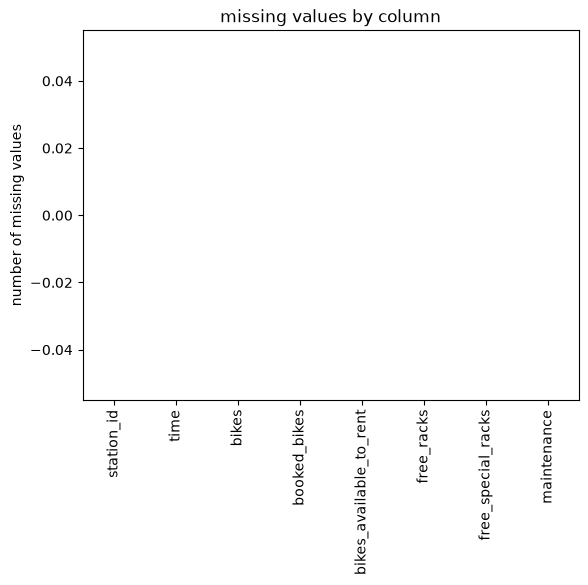

In [70]:

na_count = df.isna().sum()
print(na_count)
print((na_count / len(df) * 100).round(3), "%")

na_count.plot(kind="bar", title="missing values by column")
plt.ylabel("number of missing values")
plt.show()


We can see that there is no missing values in this dataset.



### Problem 2 : types incorrects

In [71]:

print(df.dtypes)

# conversion of time column to datetime
df["time"] = pd.to_datetime(df["time"], unit="s",  utc=True)
print("Start :", df["time"].min())
print("End   :", df["time"].max())

station_id                   int64
time                       float64
bikes                        int64
booked_bikes                 int64
bikes_available_to_rent      int64
free_racks                   int64
free_special_racks           int64
maintenance                   bool
dtype: object


Start : 2022-08-26 14:48:01+00:00
End   : 2023-07-15 21:59:01+00:00


We can see that there is no issu of time too.

### Problem 3 : duplicates

In [72]:
nb_dup = df.duplicated().sum()
print("duplicates in station_status :", nb_dup)



duplicates in station_status : 0


There is no duplicates neither.


### Problem 4 : nagative values and extreme values

negative values by column :
bikes                        0
booked_bikes               160
bikes_available_to_rent      0
free_racks                   0
free_special_racks           0
dtype: int64

Statistics :


            bikes  booked_bikes  bikes_available_to_rent  free_racks  \
count  2925967.00    2925967.00               2925967.00  2925967.00   
mean         6.19          0.05                     6.14        5.03   
std          6.09          0.40                     6.10        5.30   
min          0.00         -4.00                     0.00        0.00   
25%          3.00          0.00                     2.00        0.00   
50%          5.00          0.00                     5.00        4.00   
75%          8.00          0.00                     8.00        8.00   
max        189.00         38.00                   189.00       70.00   

       free_special_racks  
count          2925967.00  
mean                 2.22  
std                  4.34  
min                  0.00  
25%                  0.00  
50%                  0.00  
75%                  3.00  
max                 37.00  


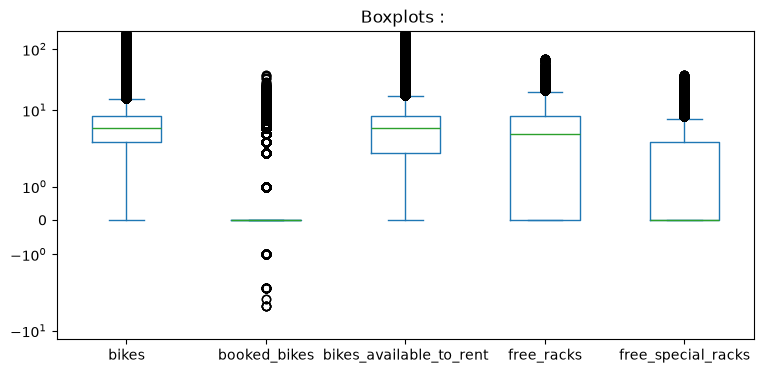

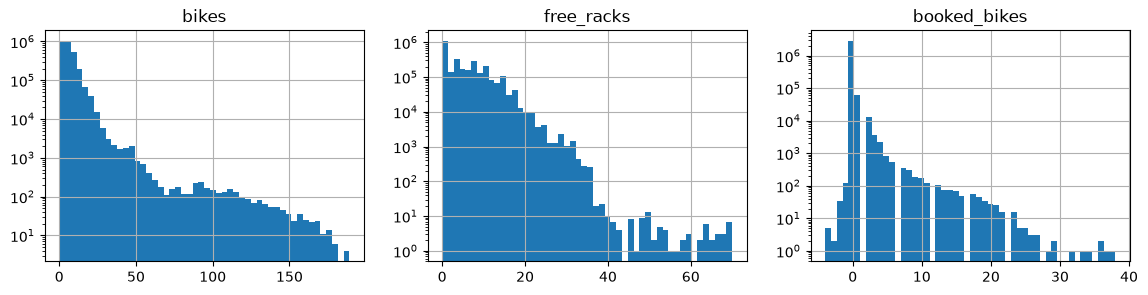

In [73]:
# negative values in columns that should be positive
cols = ["bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "free_special_racks"]

print("negative values by column :")
print((df[cols] < 0).sum())

print("\nStatistics :")
print(df[cols].describe().round(2))

# extreme values in columns 

df[cols].plot(kind="box", figsize=(9, 4), title="Boxplots : ")
plt.yscale("symlog")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
df["bikes"].hist(bins=50, ax=axes[0]);        axes[0].set_title("bikes")
df["free_racks"].hist(bins=50, ax=axes[1]);   axes[1].set_title("free_racks")
df["booked_bikes"].hist(bins=50, ax=axes[2]); axes[2].set_title("booked_bikes")
for a in axes:
    a.set_yscale("log")
plt.show()


Only booked_bikes has impossible values, 160 negatives ( at min −4) out of 2.9M rows, which represent 0.005%, so those rows can be safely removed.
All other columns are non-negative but heavily right-skewed (up to 189 bikes), so these extremes are likely large hubs and should be kept, not removed as outliers.


### Problem 5 : logical inconsistencies 

In [74]:
#a) more bikes available than bikes 
print("\n\na) Problem a : more bikes available than bikes")
pb_a = df["bikes_available_to_rent"] > df["bikes"] 
df_pb_a = df[ df["bikes_available_to_rent"] > df["bikes"] ]
print("lines with more bikes available than bikes :", len(df_pb_a), "so", round(len(df_pb_a)/len(df)*100, 2), "%")

# Is it the same lines as negative booked_bikes?
neg = df["booked_bikes"] < 0
print((neg & pb_a).sum(), "shared lines out of 160")

# b) available = bikes - booked
print("\n\nb) Problem b : available = bikes - booked")  
pb_b = df["bikes_available_to_rent"] != (df["bikes"] - df["booked_bikes"])
df_pb_b = df[pb_b]
print("lines with available != bikes - booked :", len(df_pb_b), "so", round(len(df_pb_b)/len(df)*100, 2), "%")

ecart = df.loc[pb_b, "bikes_available_to_rent"] - (df.loc[pb_b, "bikes"] - df.loc[pb_b, "booked_bikes"])
print(ecart.value_counts().head(10))

print((neg & pb_b).sum(), "shared lines out of 160")


# c) maintenance but show available bikes
print("\n\nc) Problem c : maintenance but show available bikes")
pb_c = (df["maintenance"] == True) & (df["bikes_available_to_rent"] > 0)


maint = df[df["maintenance"] == True]
print("rows under maintenance :", len(maint), "so", round(len(maint)/len(df)*100, 2), "%")
print("part of bikes_available_to_rent in those one :", round((maint["bikes_available_to_rent"] > 0).mean()*100, 1), "%")

par_station = maint.groupby("station_id").size()
print(par_station.size, "stations affected")

# change in maintenance status ?
df["maint_change"] = df.groupby("station_id")["maintenance"].diff().abs()
print(df["maint_change"].sum(), "change in maintenance status.")




a) Problem a : more bikes available than bikes
lines with more bikes available than bikes : 160 so 0.01 %
160 shared lines out of 160


b) Problem b : available = bikes - booked
lines with available != bikes - booked : 2336 so 0.08 %
1    1869
2     305
3      79
4      60
5      12
6       8
7       2
8       1
Name: count, dtype: int64
0 shared lines out of 160


c) Problem c : maintenance but show available bikes
rows under maintenance : 130542 so 4.46 %
part of bikes_available_to_rent in those one : 95.8 %
86 stations affected


10 change in maintenance status.


160 rows have negative booked_bikes (also causing available > bikes), which will be removed. Another 2,336 rows (0.08%) break available = bikes − booked due to small update lags, and will be kept.

The maintenance flag covers 4.46% of rows across 86 stations, but 95.8% of those still show available bikes and the flag almost never changes. It is therefore not a reliable “offline” indicator, so no rows will be dropped; it will be kept as a feature pending a check on whether those stations are frozen.

### Problem 6 : issus in time

In [75]:
print(df.columns.tolist())

['station_id', 'time', 'bikes', 'booked_bikes', 'bikes_available_to_rent', 'free_racks', 'free_special_racks', 'maintenance', 'maint_change']


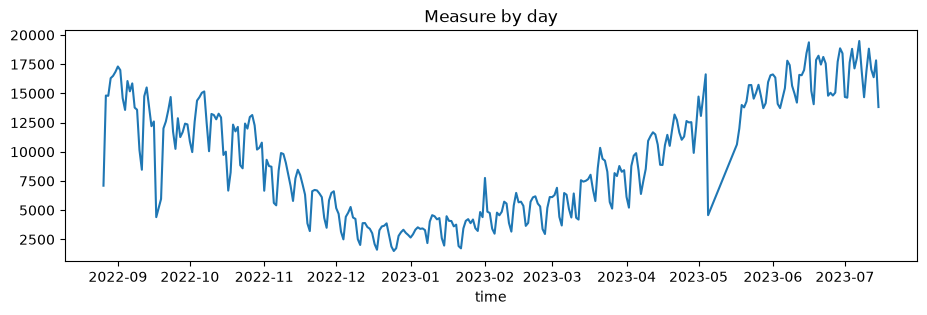

0 rows with missing timezone


['station_id', 'time', 'bikes', 'booked_bikes', 'bikes_available_to_rent', 'free_racks', 'free_special_racks', 'maintenance', 'maint_change', 'ecart_s', 'timezone', 'local_time', 'hour']
                       time       timezone          local_time  hour
0 2022-08-29 13:12:01+00:00  Europe/Berlin 2022-08-29 15:12:01    15
1 2022-08-29 13:13:01+00:00  Europe/Berlin 2022-08-29 15:13:01    15
2 2022-08-30 13:30:01+00:00  Europe/Berlin 2022-08-30 15:30:01    15
3 2022-08-31 17:57:01+00:00  Europe/Berlin 2022-08-31 19:57:01    19
4 2022-08-31 18:05:01+00:00  Europe/Berlin 2022-08-31 20:05:01    20
5 2022-09-04 15:38:01+00:00  Europe/Berlin 2022-09-04 17:38:01    17
6 2022-09-04 15:39:01+00:00  Europe/Berlin 2022-09-04 17:39:01    17
7 2022-09-05 08:32:01+00:00  Europe/Berlin 2022-09-05 10:32:01    10
8 2022-09-05 08:34:01+00:00  Europe/Berlin 2022-09-05 10:34:01    10
9 2022-09-05 08:59:01+00:00  Europe/Berlin 2022-09-05 10:59:01    10


In [76]:
df = df.sort_values(["station_id", "time"])
df["ecart_s"] = df.groupby("station_id")["time"].diff().dt.total_seconds()


# lack of measures per day
by_day = df.groupby(df["time"].dt.date).size()
by_day.plot(figsize=(11, 3), title="Measure by day")
plt.show()

# local time and timezone
stations = pd.read_csv(ROOT / "stations.csv").rename(columns={"id": "station_id"})
cities = pd.read_csv(ROOT / "cities.csv").rename(columns={"id": "city_id"})


df = df.drop(columns=["timezone", "timezone_x", "timezone_y", "local_time", "hour"], errors="ignore")


info = stations.merge(cities[["city_id", "timezone"]], on="city_id", how="left")
info = info.drop_duplicates("station_id")
df = df.merge(info[["station_id", "timezone"]], on="station_id", how="left")
print(df["timezone"].isna().sum(), "rows with missing timezone")


df["local_time"] = pd.NaT
for tz in df["timezone"].dropna().unique():
    masque = df["timezone"] == tz
    df.loc[masque, "local_time"] = df.loc[masque, "time"].dt.tz_convert(tz).dt.tz_localize(None)

df["hour"] = df["local_time"].dt.hour


print(df.columns.tolist())

print(df[["time", "timezone", "local_time", "hour"]].head(10))


All the rows have a clean time according to timezone  

In [77]:

etapes = {"begining": len(df)}
 

 
df = df[(df[cols] >= 0).all(axis=1)]
etapes["after negatives"] = len(df)
 
df = df[df["bikes_available_to_rent"] <= df["bikes"]]
etapes["after avaibility <= bikes"] = len(df)
 
# indicate if the available bikes is not equal to bikes - booked
df["availability_mismatch"] = df["bikes_available_to_rent"] != (df["bikes"] - df["booked_bikes"])

 

df = df.drop(columns=["ecart_s"])
 
print(pd.Series(etapes))
 

begining                     2925967
after negatives              2925807
after avaibility <= bikes    2925807
dtype: int64


In [78]:
df.to_csv(CLEAN_DIR / "stations_status_clean.csv", index=False)
print(df.shape)

(2925807, 13)


# 5. Trips (`trips_small.csv`)

ts2 is the cleaned trips_small table. This section explains how to get to it; if you run the whole section you get ts2 at the end.

In [79]:
import pandas as pd

In [80]:
ts = pd.read_csv(ROOT / "trips_small.csv")
ts

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1161371,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,96.0,1320.0,3061.891906
1161372,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,100.0,97.0,780.0,2178.941052
1161373,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,95.0,900.0,3061.891906
1161374,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,87.0,75.0,1020.0,4260.899309


In [81]:
ts.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681836
station_id_end      10.496514
battery_start       85.488593
battery_end         85.479207
duration             0.000000
distance             0.000000
dtype: float64

There are 4 columns with missing values:
* station_id_start with 7.68%
* station_id_end with 10.49%
* battery_start with 85.48%
* battery_end with 85.47%

The first thing to do is to check whether the missing battery values belong to electric or classic bikes.

In [82]:
ts.drop(columns=["bike_id","city_id","time_start","station_id_start","station_id_end"]).describe()

,lon_start,lat_start,lon_end,lat_end,battery_start,battery_end,duration,distance
count,1.161376e+06,1.161376e+06,1.161376e+06,1.161376e+06,168532.000000,168641.000000,1.161376e+06,1.161376e+06
mean,1.143184e+01,4.941432e+01,1.143162e+01,4.941407e+01,80.988697,76.688996,1.256241e+03,1.791774e+03
std,7.320269e+00,3.707710e+00,7.320443e+00,3.708131e+00,21.384192,22.615122,1.980838e+03,1.495191e+03
min,-1.560567e+01,2.774058e+01,-1.560567e+01,2.774058e+01,0.000000,0.000000,1.210000e+02,5.001365e+01
25%,7.165686e+00,4.717771e+01,7.165686e+00,4.717771e+01,66.000000,61.000000,4.800000e+02,8.851685e+02
50%,1.019364e+01,5.027373e+01,1.018726e+01,5.026997e+01,89.000000,83.000000,7.200000e+02,1.346711e+03
75%,1.745811e+01,5.174006e+01,1.745811e+01,5.173991e+01,100.000000,97.000000,1.200000e+03,2.238540e+03
max,3.398531e+01,5.708158e+01,3.398632e+01,5.708158e+01,100.000000,100.000000,2.874000e+04,1.999946e+04


In [83]:
bt = pd.read_csv(ROOT / "bike_types.csv")

In [84]:
b = pd.read_csv(ROOT / "bikes.csv")

In [85]:
bikes_info = b.merge(bt,how="left",left_on="bike_type_id",right_on="id",suffixes=["_bike","_bike_type"])
bikes_info.isna().mean() * 100
columns = ["computer_id","id_bike_type","vehicle_image","name","description","form_factor","rider_capacity","max_range","battery_capacity"]
bikes_info.drop(columns=columns)

,id_bike,bike_type_id,propulsion_type
0,400481,196,human
1,374044,204,electric_assist
2,373778,204,electric_assist
3,34749,14,human
4,88359,143,electric_assist
...,...,...,...
88431,372994,204,electric_assist
88432,372649,204,electric_assist
88433,372951,204,electric_assist
88434,374346,204,electric_assist


In [86]:
new_ts = ts.merge(bikes_info,how="left",left_on="bike_id",right_on="id_bike")
new_ts["propulsion_type"].value_counts(normalize=True) * 100

propulsion_type
human              84.461921
electric_assist    15.538079
Name: proportion, dtype: float64

* We can see that 84% of values in propulsion_type is human which is almost equal to 85% missing values of battery status
* We need to check if human propulsion values correspond to the missing values of the battery status

In [87]:
import numpy as np

* We convert the "human" values of the propulsion_type column to NaN

In [88]:
new_ts["propulsion_type"] = new_ts["propulsion_type"].map({"human": np.nan, "electric_assist": 1})
new_ts.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681836
station_id_end      10.496514
battery_start       85.488593
battery_end         85.479207
duration             0.000000
distance             0.000000
id_bike              0.000000
bike_type_id         0.000000
computer_id          0.000000
id_bike_type         0.000000
vehicle_image        0.202002
name                 0.202002
description         48.552923
form_factor          0.202002
rider_capacity       0.202002
propulsion_type     84.493308
max_range           84.501488
battery_capacity    84.493308
dtype: float64

* How many rows have only one missing value in the pair (battery_start, battery_end)?

In [89]:
one = new_ts[new_ts["battery_start"].notna() ^ new_ts["battery_end"].notna()]
one

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,...,computer_id,id_bike_type,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
201998,42622,676,1.670701e+09,7.219444,51.144028,7.122056,51.058917,30240427.0,32135341.0,NaN,...,7551060064,143,https://static.nextbike.net/app/biketypes/type/dl/143/h5...,e-SMARTbike 2.0 RFID,- e-eco B frame with Framelock\r\n- aluminum basket with...,bicycle,1.0,1.0,60000.0,500.0
202097,42623,676,1.684534e+09,7.197056,50.929000,7.196167,50.914278,49442475.0,32136150.0,NaN,...,7551059755,143,https://static.nextbike.net/app/biketypes/type/dl/143/h5...,e-SMARTbike 2.0 RFID,- e-eco B frame with Framelock\r\n- aluminum basket with...,bicycle,1.0,1.0,60000.0,500.0
202098,42623,676,1.684598e+09,7.196167,50.914278,7.182677,50.900797,32136150.0,30240394.0,NaN,...,7551059755,143,https://static.nextbike.net/app/biketypes/type/dl/143/h5...,e-SMARTbike 2.0 RFID,- e-eco B frame with Framelock\r\n- aluminum basket with...,bicycle,1.0,1.0,60000.0,500.0
202101,42623,676,1.684673e+09,7.182677,50.900797,7.176250,50.924389,30240394.0,32136249.0,NaN,...,7551059755,143,https://static.nextbike.net/app/biketypes/type/dl/143/h5...,e-SMARTbike 2.0 RFID,- e-eco B frame with Framelock\r\n- aluminum basket with...,bicycle,1.0,1.0,60000.0,500.0
202104,42623,676,1.685276e+09,7.184889,50.959278,7.161333,50.963972,32134268.0,30239595.0,NaN,...,7551059755,143,https://static.nextbike.net/app/biketypes/type/dl/143/h5...,e-SMARTbike 2.0 RFID,- e-eco B frame with Framelock\r\n- aluminum basket with...,bicycle,1.0,1.0,60000.0,500.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1158625,826043,679,1.684855e+09,-3.174022,51.438833,-3.179619,51.477280,30005988.0,60694214.0,NaN,...,7551094076,182,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0
1158645,826044,679,1.663164e+09,-3.206055,51.403857,-3.179534,51.484449,58569525.0,52962132.0,NaN,...,7551092436,182,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0
1158936,825564,679,1.685463e+09,-3.181851,51.448645,-3.166644,51.446057,53040980.0,6270602.0,NaN,...,7551059021,182,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0
1159834,825613,679,1.673042e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,NaN,...,7551063848,182,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0


* These battery status values are missing completely at random (MCAR) and it represents 0.01% of table rows, so we decide too delete them

In [90]:
partial = new_ts["battery_start"].isna() ^ new_ts["battery_end"].isna()
new_ts = new_ts[~partial]
new_ts.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681967
station_id_end      10.496978
battery_start       85.488086
battery_end         85.488086
duration             0.000000
distance             0.000000
id_bike              0.000000
bike_type_id         0.000000
computer_id          0.000000
id_bike_type         0.000000
vehicle_image        0.202026
name                 0.202026
description         48.558565
form_factor          0.202026
rider_capacity       0.202026
propulsion_type     84.503276
max_range           84.511457
battery_capacity    84.503276
dtype: float64

In [91]:
new_ts.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681967
station_id_end      10.496978
battery_start       85.488086
battery_end         85.488086
duration             0.000000
distance             0.000000
id_bike              0.000000
bike_type_id         0.000000
computer_id          0.000000
id_bike_type         0.000000
vehicle_image        0.202026
name                 0.202026
description         48.558565
form_factor          0.202026
rider_capacity       0.202026
propulsion_type     84.503276
max_range           84.511457
battery_capacity    84.503276
dtype: float64

* Now that we are sure that the missing values correspond to human propulsion we will replace missing values by 0 which is coherent
* The 1% more values that are missing in battery status will be considered as MCAR because we don't see any logical reason why they are missing.

In [92]:
new_ts[["battery_start", "battery_end"]] = new_ts[["battery_start", "battery_end"]].fillna(0)
new_ts.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681967
station_id_end      10.496978
battery_start        0.000000
battery_end          0.000000
duration             0.000000
distance             0.000000
id_bike              0.000000
bike_type_id         0.000000
computer_id          0.000000
id_bike_type         0.000000
vehicle_image        0.202026
name                 0.202026
description         48.558565
form_factor          0.202026
rider_capacity       0.202026
propulsion_type     84.503276
max_range           84.511457
battery_capacity    84.503276
dtype: float64

* For the station_ids that are missing we need to check whether the city allows the bikes to be returned away from stations

In [93]:
c = pd.read_csv(ROOT / "cities.csv")
c

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False
...,...,...,...,...,...,...,...
262,853,Sant Just Desvern,41.3807,2.07496,Europe/Berlin,ES,True
263,856,Sant Boi de Llobregat,41.3458,2.03404,Europe/Berlin,ES,True
264,831,Wolsztyn,52.1120,16.10560,Europe/Warsaw,PL,True
265,143,Tulln,48.3269,16.05690,Europe/Berlin,AT,False


In [94]:
c = c.rename(columns={"id": "city_id", "name": "city_name"})
ts2 = new_ts.merge(c[["city_id", "city_name", "return_to_official_only"]],
                   on="city_id", how="left", validate="m:1")

In [95]:
ts2

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,...,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity,city_name,return_to_official_only
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,0.0,...,https://static.nextbike.net/app/biketypes/type/as/15/h50...,with Fork lock,- Comfort frame typ 21 with FVM\r\n- CFC fork with CSI l...,bicycle,1.0,NaN,NaN,NaN,Wiesbaden,False
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,0.0,...,https://static.nextbike.net/app/biketypes/type/as/15/h50...,with Fork lock,- Comfort frame typ 21 with FVM\r\n- CFC fork with CSI l...,bicycle,1.0,NaN,NaN,NaN,Wiesbaden,False
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,0.0,...,https://static.nextbike.net/app/biketypes/type/as/15/h50...,with Fork lock,- Comfort frame typ 21 with FVM\r\n- CFC fork with CSI l...,bicycle,1.0,NaN,NaN,NaN,Wiesbaden,False
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,0.0,...,https://static.nextbike.net/app/biketypes/type/as/15/h50...,with Fork lock,- Comfort frame typ 21 with FVM\r\n- CFC fork with CSI l...,bicycle,1.0,NaN,NaN,NaN,Wiesbaden,False
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,0.0,...,https://static.nextbike.net/app/biketypes/type/as/15/h50...,with Fork lock,- Comfort frame typ 21 with FVM\r\n- CFC fork with CSI l...,bicycle,1.0,NaN,NaN,NaN,Wiesbaden,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1161234,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,...,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0,Penarth,True
1161235,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,100.0,...,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0,Penarth,True
1161236,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,...,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0,Penarth,True
1161237,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,87.0,...,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0,Penarth,True


In [96]:
ts2.isna().mean() * 100

bike_id                     0.000000
city_id                     0.000000
time_start                  0.000000
lon_start                   0.000000
lat_start                   0.000000
lon_end                     0.000000
lat_end                     0.000000
station_id_start            7.681967
station_id_end             10.496978
battery_start               0.000000
battery_end                 0.000000
duration                    0.000000
distance                    0.000000
id_bike                     0.000000
bike_type_id                0.000000
computer_id                 0.000000
id_bike_type                0.000000
vehicle_image               0.202026
name                        0.202026
description                48.558565
form_factor                 0.202026
rider_capacity              0.202026
propulsion_type            84.503276
max_range                  84.511457
battery_capacity           84.503276
city_name                   0.000000
return_to_official_only     0.000000
d

In [97]:
ts2["any_station_missing"] = ts2["station_id_start"].isna() | ts2["station_id_end"].isna()

base = ts2["return_to_official_only"].value_counts(normalize=True) * 100
miss = ts2.loc[ts2["any_station_missing"], "return_to_official_only"].value_counts(normalize=True) * 100
print(pd.concat([base, miss], axis=1, keys=["all trips", "station missing"]))

                         all trips  station missing
return_to_official_only                            
True                     82.706402        74.682314
False                    17.293598        25.317686


* 75% of trips with station_id that are missing require return to official station only which reject our hypothesis.
* Station ids are almost MCAR so we will delete them

In [98]:
rows = ts2["station_id_start"].isna() | ts2["station_id_end"].isna()
ts2 = ts2[~rows]
ts2.isna().mean()

bike_id                    0.000000
city_id                    0.000000
time_start                 0.000000
lon_start                  0.000000
lat_start                  0.000000
lon_end                    0.000000
lat_end                    0.000000
station_id_start           0.000000
station_id_end             0.000000
battery_start              0.000000
battery_end                0.000000
duration                   0.000000
distance                   0.000000
id_bike                    0.000000
bike_type_id               0.000000
computer_id                0.000000
id_bike_type               0.000000
vehicle_image              0.002303
name                       0.002303
description                0.452042
form_factor                0.002303
rider_capacity             0.002303
propulsion_type            0.835443
max_range                  0.835486
battery_capacity           0.835443
city_name                  0.000000
return_to_official_only    0.000000
any_station_missing        0

In [99]:

columns = ["bike_id","city_id","time_start","lon_start","lat_start","lon_end","lat_end","station_id_start","station_id_end","battery_start","battery_end","duration","distance"]
ts2 = ts2[columns]
ts2

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,0.0,0.0,1920.0,3301.514764
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,0.0,0.0,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,0.0,0.0,4680.0,897.351993
5,11463,7,1.662315e+09,8.218090,50.080828,8.242628,50.071337,4728239.0,87796472.0,0.0,0.0,600.0,2044.510274
6,11463,7,1.662542e+09,8.242628,50.071337,8.252207,50.071756,87796472.0,87797085.0,0.0,0.0,1020.0,685.223644
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1161234,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,96.0,1320.0,3061.891906
1161235,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,100.0,97.0,780.0,2178.941052
1161236,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,95.0,900.0,3061.891906
1161237,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,87.0,75.0,1020.0,4260.899309


In [100]:
ts2.to_csv(CLEAN_DIR / "trips_small_cleaned.csv", index=False)
print("Cleaned data saved to data_cleaned/trips_small_cleaned.csv")
print("Final shape:", ts2.shape)

Cleaned data saved to data_cleaned/trips_small_cleaned.csv
Final shape: (993542, 13)


# 6. Summary of the cleaned datasets

`bikes.csv` needs no cleaning (3 columns, no missing values, every `bike_type_id` exists in `bike_types`),
so it is copied unchanged next to the other cleaned files.

In [101]:
import shutil

shutil.copy(ROOT / "bikes.csv", CLEAN_DIR / "bikes.csv")

files = ["cities_clean.csv", "bike_types.csv", "bikes.csv", "cleaned_stations.csv",
         "stations_status_clean.csv", "trips_small_cleaned.csv"]
summary = pd.DataFrame([
    {"file": f, "rows": len(pd.read_csv(CLEAN_DIR / f, usecols=[0])), "columns": len(pd.read_csv(CLEAN_DIR / f, nrows=0).columns)}
    for f in files
])
summary

,file,rows,columns
0,cities_clean.csv,267,7
1,bike_types.csv,121,15
2,bikes.csv,88436,3
3,cleaned_stations.csv,2900,8
4,stations_status_clean.csv,2925807,13
5,trips_small_cleaned.csv,993542,13
